# Session 8 — Vision Tasks: Classification, Detection & Segmentation

**Question of the day:** our models know *what* a lesion is. How do we find *where* it is?

**The plan**
1. Boxes: representing them, comparing them (IoU) and cleaning duplicates (NMS).
2. Segmentation from scratch on real MILK10k lesions, with no deep learning.
3. From a mask to a box, and comparing two masks (Dice, IoU).
4. When the rules fail: other color signals, hard cases, and what labels would change.
5. Pretrained detection and segmentation models: what they can and cannot do on lesions.

**Exercises** are marked ✏️. Write your code where it says `# YOUR CODE`, then run the check cell below it: it prints ✅ when your answer is right.

**Important:** MILK10k has **no lesion masks or boxes**. When we compare two masks today, we measure how much two methods *agree*, not how *accurate* they are.

### 0. Setup

#### 0.1 Libraries and data

Only NumPy, SciPy and Pillow are needed until section 5; PyTorch and torchvision appear in section 5. Set `MILK10K_DIR` to your own MILK10k folder (the one that contains `metadata.csv` and the `images` folder).

In [1]:
# PURPOSE: load the libraries and find the MILK10k images and metadata.
# HOW: use your own folder.

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from scipy import ndimage

MILK10K_DIR = Path(r"C:/Users/Kinjal Chatterjee/Downloads/MILK10k") 

try:
    ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                if (p / "common" / "config.py").is_file())
    sys.path.insert(0, str(ROOT))
    from common import config
    IMG_DIR, METADATA = config.IMG_DIR, config.METADATA_PATH
except StopIteration:
    IMG_DIR, METADATA = Path(MILK10K_DIR) / "images", Path(MILK10K_DIR) / "metadata.csv"

meta = pd.read_csv(METADATA)
print(len(meta), "images in the metadata")      # 10480

10480 images in the metadata


**Local setup:** the dataset path is pre-filled for the Windows folder used in this project. If your MILK10k folder is somewhere else, edit `MILK10K_DIR` in the setup cell.

#### 0.2 Two small tools we will use all session

`load_rgb` opens a lesion at 300×225 pixels (half size, so everything runs fast). `check` prints ✅ or ❌ for the exercises.

In [2]:
# PURPOSE: helpers for loading images and checking exercise answers.
# HOW: load_rgb returns a float array (H, W, 3); check compares a value with the expected one.

def load_rgb(isic_id, size=(300, 225)):
    """One lesion as a float array of shape (225, 300, 3), values 0-255."""
    img = Image.open(IMG_DIR / f"{isic_id}.jpg").convert("RGB").resize(size)
    return np.array(img, dtype=float)

def check(name, got, expected, tol=1e-3):
    """Print ✅ if `got` equals `expected` (numbers: within `tol`)."""
    try:
        ok = np.allclose(got, expected, atol=tol) if np.ndim(expected) or isinstance(expected, float) else got == expected
    except Exception:
        ok = False
    print(("✅ " if ok else "❌ ") + f"{name}: got {got}, expected {expected}")

lesion = load_rgb("ISIC_0073863")               # our usual lesion (a nevus)
print(lesion.shape)                             # (225, 300, 3): rows, columns, channels

(225, 300, 3)


### 1. Boxes and IoU

#### 1.1 How a box is written · *slide 7*

A box is 4 numbers. The two common formats are **(x1, y1, x2, y2)**, the top-left and bottom-right corners, and **(cx, cy, w, h)**, the center plus width and height. As in Session 2, **y grows downwards**. We use the corner format all session.

(152.5, 107.5, 161, 127)


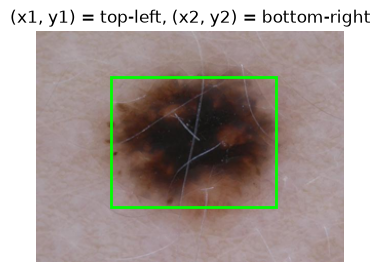

In [3]:
# PURPOSE: convert between the two box formats and draw a box on the lesion.
# HOW: the center is the midpoint of the corners; width and height are differences.

def xyxy_to_cxcywh(box):
    x1, y1, x2, y2 = box
    return ((x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1)

box = (72, 44, 233, 171)                        # a box around the lesion, (x1, y1, x2, y2)
print(xyxy_to_cxcywh(box))                      # (152.5, 107.5, 161, 127)

fig, ax = plt.subplots(figsize=(4, 3))
ax.imshow(lesion.astype(np.uint8))
ax.add_patch(patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], fill=False, color="lime", lw=2))
ax.set_title("(x1, y1) = top-left, (x2, y2) = bottom-right"); ax.axis("off");

#### ✏️ Exercise 1 — IoU of two boxes (≈ 6 min) · *slides 8–9*

IoU = **area of the overlap ÷ area of the union**.

1. The overlap is a box too: its left edge is the larger of the two left edges, and its right edge is the smaller of the two right edges (the same for top and bottom).
2. If the boxes don't touch, that "box" has a negative width or height: the overlap must be **0**, not negative.
3. union = area A + area B − overlap.

In [4]:
def iou(box_a, box_b):
    """IoU of two boxes in (x1, y1, x2, y2) format."""
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    # Corners of the intersection
    x1 = max(ax1, bx1)
    y1 = max(ay1, by1)
    x2 = min(ax2, bx2)
    y2 = min(ay2, by2)

    # Intersection area (zero if the boxes do not overlap)
    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)
    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

In [5]:
# CHECK Exercise 1 — the slide's example: areas 100 and 120, overlap 80 -> 80 / 140
check("slide example", iou((0, 0, 10, 10), (2, 0, 14, 10)), 80 / 140)
check("same box", iou((0, 0, 10, 10), (0, 0, 10, 10)), 1.0)
check("boxes that don't touch", iou((0, 0, 10, 10), (20, 20, 30, 30)), 0.0)
check("one box inside the other", iou((0, 0, 10, 10), (2, 2, 7, 7)), 25 / 100)

✅ slide example: got 0.5714285714285714, expected 0.5714285714285714
✅ same box: got 1.0, expected 1.0
✅ boxes that don't touch: got 0.0, expected 0.0
✅ one box inside the other: got 0.25, expected 0.25


### 2. Non-max suppression (NMS) · *slides 12–13*

#### 2.1 A detector's raw output: many boxes for one lesion

Detectors propose many overlapping boxes around the same object, each with a confidence score. Here are five candidates for our lesion.

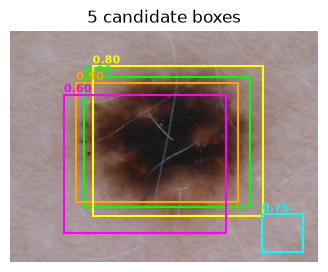

In [6]:
# PURPOSE: simulate the raw output of a detector: 5 boxes with confidence scores.
# HOW: four boxes around the lesion and one box on another part of the image.

cand_boxes = [(72, 44, 233, 171), (64, 50, 222, 166), (80, 34, 246, 180), (245, 178, 285, 215), (52, 62, 210, 196)]
cand_scores = [0.95, 0.90, 0.80, 0.75, 0.60]

fig, ax = plt.subplots(figsize=(4, 3))
ax.imshow(lesion.astype(np.uint8))
for (x1, y1, x2, y2), s, c in zip(cand_boxes, cand_scores, ["lime", "orange", "yellow", "cyan", "magenta"]):
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=c, lw=1.5))
    ax.text(x1, y1 - 3, f"{s:.2f}", color=c, fontsize=8, fontweight="bold")
ax.set_title("5 candidate boxes"); ax.axis("off");

#### ✏️ Exercise 2 — implement NMS (≈ 10 min)

1. Sort the boxes by score, highest first.
2. Keep the best remaining box.
3. Remove every remaining box whose IoU with it is **above** the threshold (they are duplicates).
4. Repeat until no box is left. Return the **indices** of the kept boxes, best first.

Use your `iou` from Exercise 1.

In [7]:
def nms(boxes, scores, threshold=0.5):
    """Indices of the boxes kept by non-max suppression, highest score first."""
    boxes = [tuple(box) for box in boxes]
    scores = np.asarray(scores)

    # Start with indices sorted from highest to lowest confidence.
    order = np.argsort(scores)[::-1]
    kept = []

    while len(order) > 0:
        best = int(order[0])
        kept.append(best)

        # Compare the best box with all remaining boxes.
        remaining = order[1:]
        survivors = []
        for idx in remaining:
            if iou(boxes[best], boxes[int(idx)]) <= threshold:
                survivors.append(int(idx))

        order = np.asarray(survivors, dtype=int)

    return kept

In [8]:
# CHECK Exercise 2 — on our 5 boxes, and against torchvision's own NMS on 50 random boxes
check("our 5 candidates", nms(cand_boxes, cand_scores), [0, 3])

import torch
from torchvision.ops import nms as torch_nms
rng = np.random.default_rng(0)
xy = rng.uniform(0, 200, (50, 2)); wh = rng.uniform(20, 80, (50, 2))
rand_boxes = np.hstack([xy, xy + wh]); rand_scores = rng.uniform(0, 1, 50)
expected = torch_nms(torch.tensor(rand_boxes), torch.tensor(rand_scores), 0.5).tolist()
check("50 random boxes vs torchvision", nms([tuple(b) for b in rand_boxes], rand_scores), expected)

✅ our 5 candidates: got [0, 3], expected [0, 3]
✅ 50 random boxes vs torchvision: got [39, 41, 6, 20, 47, 18, 16, 24, 49, 37, 42, 33, 19, 9, 30, 28, 2, 46, 25, 45, 5, 35, 4, 32, 8, 26, 43, 17, 31, 15, 11, 0, 29, 36, 3, 1, 40, 10, 27, 21, 34, 14, 22, 7, 23, 48, 12], expected [39, 41, 6, 20, 47, 18, 16, 24, 49, 37, 42, 33, 19, 9, 30, 28, 2, 46, 25, 45, 5, 35, 4, 32, 8, 26, 43, 17, 31, 15, 11, 0, 29, 36, 3, 1, 40, 10, 27, 21, 34, 14, 22, 7, 23, 48, 12]


#### 2.2 After NMS

One box is left for the lesion. Box 3 also survives, because it doesn't overlap the lesion box at all. NMS only removes **duplicates**: discarding false alarms like box 3 is the job of the confidence threshold.

box 0  score 0.95  IoU with box 0 = 1.00
box 1  score 0.90  IoU with box 0 = 0.81
box 2  score 0.80  IoU with box 0 = 0.77
box 3  score 0.75  IoU with box 0 = 0.00
box 4  score 0.60  IoU with box 0 = 0.57


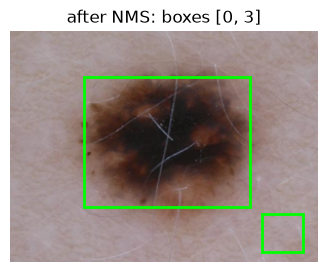

In [9]:
# PURPOSE: see what NMS kept, and the IoU of each candidate with the best box.
# HOW: print the IoUs, then draw only the kept boxes.

for i, b in enumerate(cand_boxes):
    print(f"box {i}  score {cand_scores[i]:.2f}  IoU with box 0 = {iou(cand_boxes[0], b):.2f}")

kept = nms(cand_boxes, cand_scores)
fig, ax = plt.subplots(figsize=(4, 3))
ax.imshow(lesion.astype(np.uint8))
for i in kept:
    x1, y1, x2, y2 = cand_boxes[i]
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", lw=2))
ax.set_title(f"after NMS: boxes {kept}"); ax.axis("off");

### 3. Segmentation from scratch

#### 3.1 Step by step on one lesion · *slides 26–29*

A classical pipeline with tools from Sessions 2 and 4: a **darkness** score per pixel, a **Gaussian blur**, a **threshold**, then **morphology** to clean up the mask and keep **the largest region**.

1 region(s) after cleaning; the lesion covers 22% of the image


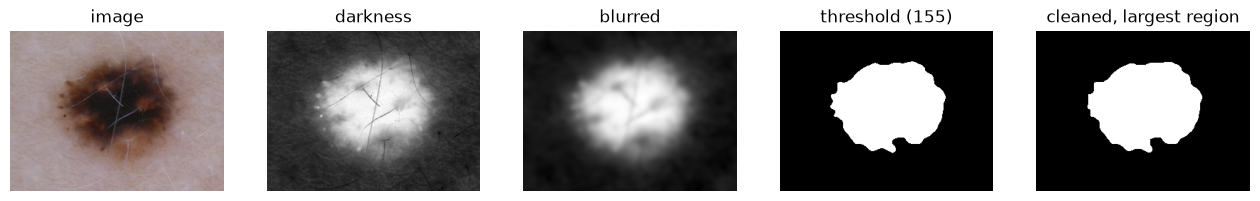

In [10]:
# PURPOSE: build a lesion mask, one visible step at a time.
# HOW: every step is one or two lines of NumPy/SciPy; we keep each result to plot it.

gray = 0.299 * lesion[..., 0] + 0.587 * lesion[..., 1] + 0.114 * lesion[..., 2]   # Session 2 luminance
darkness = 255 - gray                                   # high = dark = probably lesion
smooth = ndimage.gaussian_filter(darkness, sigma=3)     # Session 4 blur: removes noise and thin hairs
threshold = np.percentile(smooth, 78)                   # keep the darkest 22% of pixels
raw_mask = smooth > threshold

# Morphology: closing fills small gaps, opening removes small specks, fill_holes fills holes inside
clean = ndimage.binary_closing(raw_mask, structure=np.ones((9, 9)))
clean = ndimage.binary_opening(clean, structure=np.ones((5, 5)))
clean = ndimage.binary_fill_holes(clean)

# Keep only the largest connected region (label numbers each separate blob 1, 2, 3, ...)
labeled, n_regions = ndimage.label(clean)
sizes = ndimage.sum(clean, labeled, range(1, n_regions + 1))
mask = labeled == (np.argmax(sizes) + 1)
print(f"{n_regions} region(s) after cleaning; the lesion covers {mask.mean():.0%} of the image")

steps = [lesion.astype(np.uint8), darkness, smooth, raw_mask, mask]
titles = ["image", "darkness", "blurred", f"threshold ({threshold:.0f})", "cleaned, largest region"]
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, im, t in zip(axes, steps, titles):
    ax.imshow(im, cmap=None if im.ndim == 3 else "gray"); ax.set_title(t); ax.axis("off")

#### 3.2 The whole pipeline as one function

The same steps, packaged so we can reuse them. `score` is the per-pixel signal (darkness today; something else in section 4) and `threshold_fn` chooses the cut.

In [11]:
# PURPOSE: one reusable segmentation function.
# HOW: the same steps as cell 3.1; the signal and the threshold rule are parameters.

def segment(score, threshold_fn=lambda s: np.percentile(s, 78)):
    """Boolean mask of the largest region where the blurred score is above the threshold."""
    smooth = ndimage.gaussian_filter(score, sigma=3)
    m = smooth > threshold_fn(smooth)
    m = ndimage.binary_closing(m, structure=np.ones((9, 9)))
    m = ndimage.binary_opening(m, structure=np.ones((5, 5)))
    m = ndimage.binary_fill_holes(m)
    labeled, n = ndimage.label(m)
    if n == 0:
        return m
    sizes = ndimage.sum(m, labeled, range(1, n + 1))
    return labeled == (np.argmax(sizes) + 1)

def darkness_of(rgb):
    return 255 - (0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2])

mask = segment(darkness_of(lesion))
print(mask.shape, mask.dtype, f"{mask.mean():.0%} of the pixels")   # (225, 300) bool

(225, 300) bool 22% of the pixels


#### ✏️ Exercise 3 — from a mask to a box (≈ 4 min) · *slide 26*

A mask gives a box for free: the box goes from the leftmost to the rightmost lesion pixel, and from the top one to the bottom one.

- `np.where(mask)` returns two arrays: the **rows** (y) and the **columns** (x) of every True pixel.
- Return `(x1, y1, x2, y2)` with **x2 = largest column + 1** and **y2 = largest row + 1**, so that `x2 − x1` is the box width in pixels, the same convention as `iou`.

In [12]:
def mask_to_bbox(mask):
    """Smallest box (x1, y1, x2, y2) that contains every True pixel."""
    ys, xs = np.where(np.asarray(mask, dtype=bool))

    if len(xs) == 0:
        return None

    # Add 1 to max coordinates because the right/bottom edges are exclusive.
    return (int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1)

In [13]:
# CHECK Exercise 3 — a toy mask: True in rows 2-4 and columns 1-5
toy = np.zeros((8, 8), dtype=bool)
toy[2:5, 1:6] = True
check("toy mask", mask_to_bbox(toy), (1, 2, 6, 5))
check("box width = 5 pixels", mask_to_bbox(toy)[2] - mask_to_bbox(toy)[0], 5)

✅ toy mask: got (1, 2, 6, 5), expected (1, 2, 6, 5)
✅ box width = 5 pixels: got 5, expected 5


#### 3.3 One lesion, three tasks · *slide 5*

With a mask and its box, we can draw the three outputs of Part 1 on the same image. The classification label here is only illustrative.

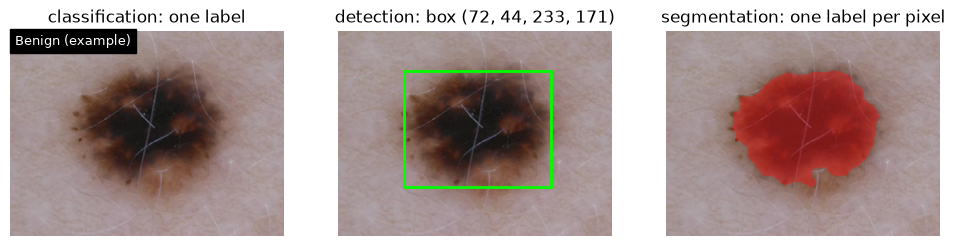

In [14]:
# PURPOSE: reproduce the "same lesion, three outputs" figure from the slides.
# HOW: a text label, the box from the mask, and the mask as a red overlay.

box = mask_to_bbox(mask)
overlay = lesion.copy()
overlay[mask] = 0.5 * overlay[mask] + 0.5 * np.array([230, 30, 30])   # tint the lesion pixels red

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax in axes:
    ax.axis("off")
axes[0].imshow(lesion.astype(np.uint8)); axes[0].set_title("classification: one label")
axes[0].text(5, 15, "Benign (example)", color="white", backgroundcolor="black", fontsize=9)
axes[1].imshow(lesion.astype(np.uint8)); axes[1].set_title(f"detection: box {box}")
axes[1].add_patch(patches.Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, color="lime", lw=2))
axes[2].imshow(overlay.astype(np.uint8)); axes[2].set_title("segmentation: one label per pixel");

#### ✏️ Exercise 4 — comparing two masks: Dice and IoU (≈ 6 min) · *slides 22–23*

For two boolean masks A and B of the same shape:

- **IoU** = |A ∩ B| / |A ∪ B|  → `np.logical_and`, `np.logical_or`, `.sum()`
- **Dice** = 2·|A ∩ B| / (|A| + |B|)  → `.sum()` of each mask counts its pixels

In [15]:
def mask_iou(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    intersection = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return float(intersection / union) if union > 0 else 1.0


def dice(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    intersection = np.logical_and(a, b).sum()
    total = a.sum() + b.sum()
    return float(2 * intersection / total) if total > 0 else 1.0

In [16]:
# CHECK Exercise 4 — the slide's example: 900 predicted pixels, 1,000 true pixels, 800 in common
true_mask = np.zeros(2000, dtype=bool); true_mask[0:1000] = True       # 1,000 pixels
pred_mask = np.zeros(2000, dtype=bool); pred_mask[200:1100] = True     #   900 pixels, overlap 800
check("IoU  = 800 / 1100", mask_iou(pred_mask, true_mask), 800 / 1100)
check("Dice = 1600 / 1900", dice(pred_mask, true_mask), 1600 / 1900)

✅ IoU  = 800 / 1100: got 0.7272727272727273, expected 0.7272727272727273
✅ Dice = 1600 / 1900: got 0.8421052631578947, expected 0.8421052631578947


#### 3.4 How much does the threshold matter?

We segment the same lesion with three thresholds and compare the masks. Remember: this is **agreement between methods**, because MILK10k gives us no true mask.

percentile 70: area 30%   Dice vs 78 = 0.85   IoU vs 78 = 0.73
percentile 78: area 22%   Dice vs 78 = 1.00   IoU vs 78 = 1.00
percentile 85: area 15%   Dice vs 78 = 0.82   IoU vs 78 = 0.69


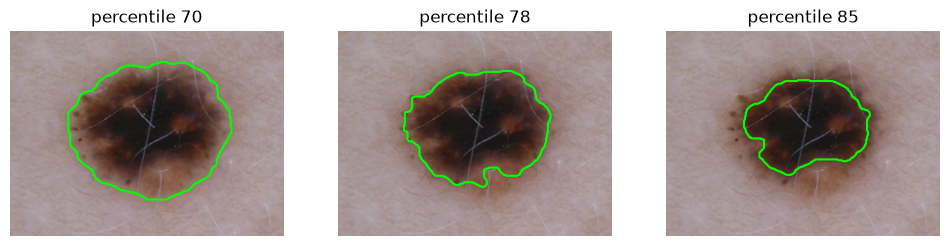

In [17]:
# PURPOSE: measure how sensitive the mask is to the threshold choice.
# HOW: segment with the 70th, 78th and 85th percentiles; compare each with the 78th.

masks = {p: segment(darkness_of(lesion), lambda s, p=p: np.percentile(s, p)) for p in (70, 78, 85)}
for p, m in masks.items():
    print(f"percentile {p}: area {m.mean():.0%}   Dice vs 78 = {dice(m, masks[78]):.2f}   IoU vs 78 = {mask_iou(m, masks[78]):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (p, m) in zip(axes, masks.items()):
    ax.imshow(lesion.astype(np.uint8)); ax.contour(m, colors="lime", linewidths=1.5)
    ax.set_title(f"percentile {p}"); ax.axis("off")

### 4. When the simple rule fails

#### 4.1 An automatic threshold: Otsu's method · *slide 28*

Instead of guessing a percentile, Otsu's method looks at the histogram (Session 2) and picks the cut that best splits the pixels into two groups: it maximizes **w₀ · w₁ · (μ₀ − μ₁)²**, where w₀, w₁ are the numbers of pixels below and above the cut and μ₀, μ₁ their mean values: two groups that are far apart and both sizeable.

Otsu vs 78th percentile: Dice = 0.99


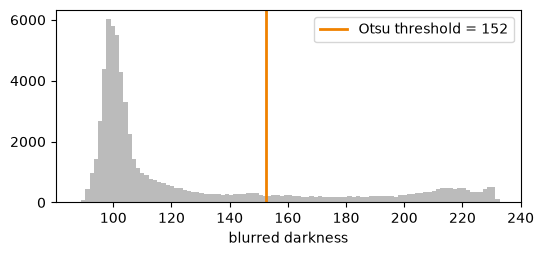

In [18]:
# PURPOSE: choose the threshold from the data instead of fixing a percentile.
# HOW: try every possible cut of the histogram and keep the one with the largest between-group variance.

def otsu(values, bins=256):
    hist, edges = np.histogram(values, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(hist)                                   # pixels below each cut
    w1 = w0[-1] - w0                                       # pixels above each cut
    m0 = np.cumsum(hist * centers) / np.maximum(w0, 1)     # mean below
    m1 = ((hist * centers).sum() - np.cumsum(hist * centers)) / np.maximum(w1, 1)   # mean above
    return centers[np.argmax(w0 * w1 * (m0 - m1) ** 2)]

t = otsu(ndimage.gaussian_filter(darkness_of(lesion), 3))
plt.figure(figsize=(6, 2.5))
plt.hist(ndimage.gaussian_filter(darkness_of(lesion), 3).ravel(), bins=100, color="#BBBBBB")
plt.axvline(t, color="#F08200", lw=2, label=f"Otsu threshold = {t:.0f}"); plt.legend(); plt.xlabel("blurred darkness");

mask_otsu = segment(darkness_of(lesion), otsu)
print(f"Otsu vs 78th percentile: Dice = {dice(mask_otsu, masks[78]):.2f}")

#### 4.2 A pink lesion: darkness is the wrong signal

Many BCCs are **pink, not dark**. Darkness then picks shadows or the image corners instead.

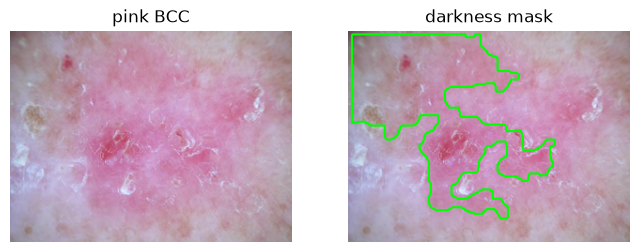

In [19]:
# PURPOSE: see the darkness rule fail on a non-pigmented lesion.
# HOW: same pipeline, with Otsu's threshold, on a pink BCC.

pink = load_rgb("ISIC_0081055")                 # basal cell carcinoma, pink
mask_dark = segment(darkness_of(pink), otsu)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(pink.astype(np.uint8)); axes[0].set_title("pink BCC")
axes[1].imshow(pink.astype(np.uint8)); axes[1].contour(mask_dark, colors="lime", linewidths=1.5); axes[1].set_title("darkness mask")
for ax in axes:
    ax.axis("off")

#### ✏️ Exercise 5 — segment with saturation instead (≈ 8 min) · *slide 30*

**Saturation** measures how vivid a color is, rather than how dark it is: gray skin is low, pink or brown lesions are higher. For each pixel:

saturation = (max(R, G, B) − min(R, G, B)) / max(R, G, B)

1. Write `saturation_of(rgb)`; use `rgb.max(axis=2)` and `rgb.min(axis=2)`, and avoid dividing by 0.
2. Segment the pink BCC with `segment(saturation_of(pink), otsu)`.
3. Compare it with the darkness mask using your `dice`, and look at both masks.

In [20]:
def saturation_of(rgb):
    """Return HSV-style saturation in the range 0-1 for an RGB image."""
    rgb = np.asarray(rgb, dtype=float)
    channel_max = rgb.max(axis=-1)
    channel_min = rgb.min(axis=-1)
    delta = channel_max - channel_min

    saturation = np.zeros_like(channel_max, dtype=float)
    np.divide(delta, channel_max, out=saturation, where=channel_max > 0)
    return saturation


mask_sat = segment(saturation_of(pink), otsu)

✅ saturation of gray, red, pink: got [0.    1.    0.333], expected [0.    1.    0.333]
Dice between the darkness and saturation masks: 0.55


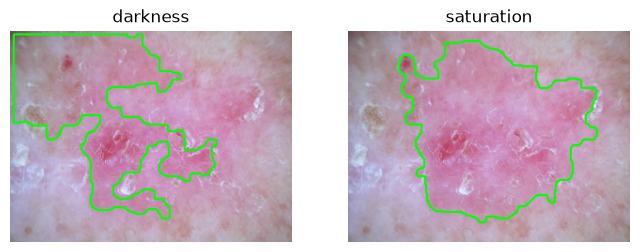

In [21]:
# CHECK Exercise 5 — the formula on three pixels: gray, pure red, pink
px = np.array([[[128., 128., 128.], [255., 0., 0.], [240., 160., 200.]]])
check("saturation of gray, red, pink", np.round(saturation_of(px)[0], 3), np.array([0.0, 1.0, 0.333]))

print(f"Dice between the darkness and saturation masks: {dice(mask_dark, mask_sat):.2f}")
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, m, t in zip(axes, [mask_dark, mask_sat], ["darkness", "saturation"]):
    ax.imshow(pink.astype(np.uint8)); ax.contour(m, colors="lime", linewidths=1.5); ax.set_title(t); ax.axis("off")

#### 4.3 Hard cases: which mask is right? · *slide 31*

Four lesions, two methods. Look for hairs, a lesion that is barely visible, and a photo with **two lesions**: "keep the largest region" can only return one of them, which is the difference between semantic and instance segmentation from Part 1.

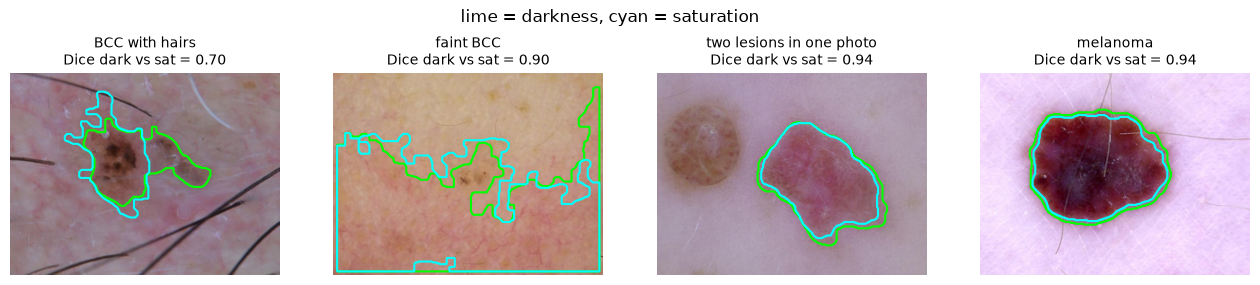

In [22]:
# PURPOSE: look at the limits of hand-made rules on difficult images.
# HOW: segment 4 lesions with darkness and saturation, and draw both contours.

hard = {"ISIC_0077054": "BCC with hairs", "ISIC_0076255": "faint BCC",
        "ISIC_0124902": "two lesions in one photo", "ISIC_0156507": "melanoma"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (i, title) in zip(axes, hard.items()):
    rgb = load_rgb(i)
    m_dark, m_sat = segment(darkness_of(rgb), otsu), segment(saturation_of(rgb), otsu)
    ax.imshow(rgb.astype(np.uint8))
    ax.contour(m_dark, colors="lime", linewidths=1.5); ax.contour(m_sat, colors="cyan", linewidths=1.5)
    ax.set_title(f"{title}\nDice dark vs sat = {dice(m_dark, m_sat):.2f}", fontsize=10); ax.axis("off")
fig.suptitle("lime = darkness, cyan = saturation");

**Without a true mask we cannot say which contour is correct.** And agreement is not accuracy: on the faint BCC both methods agree (high Dice), yet both outline the skin. That's the real reason to pay for pixel labels, and to train a U-Net on them.

#### 4.4 What a mask is good for: shape features

Session 5's ABCD rule needs the lesion's shape, and a mask gives it to us. First, the simplest one: how much of the image the lesion covers, over 300 lesions.

In [23]:
# PURPOSE: turn masks into a number per lesion and compare diagnoses.
# HOW: segment 300 dermoscopic images (about 15 s) and average the lesion area per diagnosis.

der = meta[meta["image_type"] == "dermoscopic"].sample(300, random_state=0)
t0 = time.perf_counter()
der["area"] = [segment(darkness_of(load_rgb(i)), otsu).mean() for i in der["isic_id"]]
print(f"{time.perf_counter() - t0:.0f} s")
der.groupby("diagnosis_1")["area"].describe()[["count", "mean", "50%"]].round(2)

5 s


,count,mean,50%
diagnosis_1,,,
Benign,76.0,0.28,0.25
Indeterminate,10.0,0.30,0.30
Malignant,214.0,0.26,0.23


#### ✏️ Exercise 6 — an asymmetry score (≈ 8 min) · *slide 32*

The **A** of ABCD. Crop the mask to its box, flip it left-right, and compare it with itself:

asymmetry = 1 − Dice(cropped mask, flipped cropped mask)

0 means perfectly symmetric. Use `mask_to_bbox`, slicing `m[y1:y2, x1:x2]`, `np.fliplr` and your `dice`.

In [24]:
def asymmetry(m):
    """Measure left-right asymmetry of a binary mask (0 = symmetric)."""
    m = np.asarray(m, dtype=bool)

    bbox = mask_to_bbox(m)
    if bbox is None:
        return 0.0

    x1, y1, x2, y2 = bbox
    cropped = m[y1:y2, x1:x2]
    flipped = np.fliplr(cropped)

    # Fraction of foreground pixels that do not match after reflection.
    return float(np.logical_xor(cropped, flipped).sum() / (2 * cropped.sum())) if cropped.sum() else 0.0

In [25]:
# CHECK Exercise 6 — a symmetric rectangle (0) and an L shape (clearly above 0)
rect = np.zeros((10, 10), dtype=bool); rect[2:8, 3:7] = True
ell = np.zeros((10, 10), dtype=bool); ell[2:8, 2:4] = True; ell[6:8, 2:8] = True
check("symmetric rectangle", asymmetry(rect), 0.0)
check("L shape", round(asymmetry(ell), 3), 0.4)
print(f"our lesion: asymmetry = {asymmetry(mask):.2f}")

✅ symmetric rectangle: got 0.0, expected 0.0
✅ L shape: got 0.4, expected 0.4
our lesion: asymmetry = 0.07


### 5. Pretrained detection and segmentation models · *slide 32*

#### 5.1 A detector trained on COCO

torchvision ships complete detectors. This one was trained on **COCO**: everyday objects such as people, cats and cars. Its output is exactly Part 1's list of (box, class, confidence).

In [26]:
# PURPOSE: run a real pretrained detector on our lesion.
# HOW: load Faster R-CNN (MobileNet backbone, light enough for a laptop CPU) and look at its top predictions.

import torch
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn, FasterRCNN_MobileNet_V3_Large_FPN_Weights

weights = FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT
detector = fasterrcnn_mobilenet_v3_large_fpn(weights=weights).eval()      # downloads ~75 MB the first time

big = load_rgb("ISIC_0073863", size=(600, 450))
x = torch.from_numpy(big).permute(2, 0, 1).float() / 255                   # (3, H, W), values 0-1
with torch.no_grad():
    pred = detector([x])[0]                                                # a list in, a list out

names = weights.meta["categories"]
for b, l, s in zip(pred["boxes"][:3], pred["labels"][:3], pred["scores"][:3]):
    print(f"{names[l]:10s} confidence {s:.2f}  box {b.round().tolist()}")

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to C:\Users\Kinjal Chatterjee/.cache\torch\hub\checkpoints\fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100.0%


cat        confidence 0.68  box [127.0, 66.0, 490.0, 330.0]
cat        confidence 0.10  box [138.0, 140.0, 404.0, 303.0]
umbrella   confidence 0.10  box [65.0, 25.0, 540.0, 418.0]


The architecture works, but **its classes are wrong for us**: it only knows COCO's 80 object types, and a nevus is not one of them.

#### 5.2 A segmenter trained on everyday objects

The same lesson with DeepLabV3. It was trained on 21 classes (person, dog, car, …, plus background).

In [27]:
# PURPOSE: run a pretrained segmentation model on the lesion.
# HOW: the output has one score map per class; argmax picks the class of each pixel.

from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large, DeepLabV3_MobileNet_V3_Large_Weights

sweights = DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT
segmenter = deeplabv3_mobilenet_v3_large(weights=sweights).eval()         # downloads ~45 MB the first time
with torch.no_grad():
    out = segmenter(sweights.transforms()(x).unsqueeze(0))["out"]         # (1, 21 classes, H, W)
pred_mask = out.argmax(dim=1)[0]                                          # (H, W): one class per pixel

classes = sweights.meta["categories"]
print(out.shape)
print({classes[k]: f"{(pred_mask == k).float().mean():.0%}" for k in pred_mask.unique().tolist()})

0.3%

Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to C:\Users\Kinjal Chatterjee/.cache\torch\hub\checkpoints\deeplabv3_mobilenet_v3_large-fc3c493d.pth


100.0%


torch.Size([1, 21, 520, 693])
{'__background__': '100%'}


**What fine-tuning would need:** the same transfer learning as Session 7, but with a new head for "lesion vs. background", trained on **lesion boxes or masks**. MILK10k doesn't have them; ISIC 2018 Task 1, for example, has 2,594 expert lesion masks.

### 6. Wrap-up

- **Boxes:** IoU measures overlap, and NMS uses IoU to remove duplicates.
- **Masks:** a classical pipeline (signal → blur → threshold → morphology → largest region) works on dark lesions and fails on pink, faint or multiple lesions.
- **A mask gives you more:** a box, and shape features such as area and asymmetry.
- **Pretrained models:** the architecture is ready, but useful detection or segmentation of lesions needs lesion labels.